# NOx EMG Member Diagnostics

Visual inspection of the EMG retrieval for the **canonical (nb03)** parameters and
selected MC ensemble members (notebook 08), using the same plot style as nb03.

**Purpose:** understand why the MC median (≈4,844 g/s) is well below the canonical
point estimate (7,929 g/s) by inspecting:
- The rotated NO₂ field (pcolormesh in wind-aligned coordinates)
- The line density profile with EMG fit

Members are selected at key percentiles of the MC E(NOₓ) distribution.
The re-run uses the **full pixel set** (no bootstrap resampling) for clean
visualisation; stored MC E values may differ slightly.

> Blue border = canonical; black border = MC member.

In [1]:
import sys, glob, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

ROOT = Path('.').resolve()
while not ((ROOT / 'src').exists() and (ROOT / 'data').exists()):
    if ROOT == ROOT.parent:
        raise RuntimeError('Could not locate project root (need src/ and data/).')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data_helpers import load_no2_l2, get_modis_hotspot
from src.emg_utils import (
    rotate_to_wind_frame, bin_to_grid, build_line_density,
    fit_emg_bootstrap, emg,
)

print('Project root:', ROOT)

Project root: /Users/maperezc/Downloads/wildfires


In [2]:
# ── Config (mirrors nb08 exactly) ─────────────────────────────────────────
FIRE_DATE  = '2026-01-18'
TARGET_DAY = '0118'
DATA       = ROOT / 'data'
OUT_DIR    = ROOT / 'outputs' / 'error_mc' / TARGET_DAY
MC_CSV     = OUT_DIR / 'nox_error_members.csv'
HOTSPOT_CSV = DATA / 'daily_dominant_hotspot_summary.csv'

LAT_MIN, LAT_MAX = -66.83, -6.83
LON_MIN, LON_MAX = -103.05, -43.05
QA_UINT8 = 50

DOWNWIND_MIN_KM     = -100.0
NOX_NO2_RATIO_GAMMA = 1.32
NO2_MOLAR_MASS      = 46.005
MIN_X0_KM           = 0.05 * 111.32   # ≈ 5.57 km — grid-cell-size lower bound
BOOTSTRAP_ITERS     = 50              # more than nb08 for stable diagnostic fits
BOOTSTRAP_SEED      = 42

# Canonical nb03 parameters (from outputs/retrievals/0118/nox_retrieval.csv)
CANON_THETA_DEG   = 120.2   # wind direction at 885 hPa (ERA5)
CANON_WIND_MS     = 8.76    # |U| at 885 hPa
CANON_PRESS_HPA   = 885.0
CANON_E_GS        = 7928.6  # reference emission (g/s NOx)
CANON_EXTRACT_KM  = 450.0
CANON_DW_MAX_KM   = 450.0
CANON_CW_KM       = 100.0
CANON_GRID_DY_KM  = 0.05 * 111.32

In [3]:
# ── Load NO₂ L2 data and canonical centroid ───────────────────────────────
modis = get_modis_hotspot(HOTSPOT_CSV, FIRE_DATE,
                          lat_min=LAT_MIN, lat_max=LAT_MAX,
                          lon_min=LON_MIN, lon_max=LON_MAX)
FIRE_LAT = float(modis['dominant_lat'].values[0])
FIRE_LON = float(modis['dominant_lon'].values[0])
print(f'Canonical centroid: ({FIRE_LAT:.4f}°S, {FIRE_LON:.4f}°E)')

df = pd.read_csv(MC_CSV)
E_arr = df['E_nox_g_per_s'].values
print(f'MC members: {len(df)}')
print(f'E(NOx): median={np.median(E_arr):.0f}  mean={np.mean(E_arr):.0f}  '
      f'[p10={np.percentile(E_arr,10):.0f}, p90={np.percentile(E_arr,90):.0f}] g/s')

Canonical centroid: (-37.5484°S, -72.5545°E)
NO₂ pixels: 521,236
MC members: 284
E(NOx): median=7450  mean=7359  [p10=4677, p90=8829] g/s


In [16]:
from collections import defaultdict

def load_and_concat(paths, loader, **kwargs):
    chunks = defaultdict(list)
    scalars = {}
    for pth in paths:
        pth = Path(pth)
        data = loader(pth, **kwargs)
        if data is None:
            continue  # skip orbits with no valid pixels in the ROI
        for k, v in data.items():
            if isinstance(v, np.ndarray):
                chunks[k].append(v)
            else:
                scalars[k] = v
    out = {k: np.concatenate(v) for k, v in chunks.items()}
    out.update(scalars)
    return out


roi_kwargs = dict(
    lat_min=LAT_MIN,
    lat_max=LAT_MAX,
    lon_min=LON_MIN,
    lon_max=LON_MAX,
    qa_threshold=QA_UINT8,
)
NO2_L2_PATTERN   = DATA / TARGET_DAY / "S5P_OFFL_L2__NO2____2026*"
NO2_L2_PATH    = glob.glob(str(NO2_L2_PATTERN))
no2 = load_and_concat(NO2_L2_PATH, load_no2_l2, **roi_kwargs)

no2_lat, no2_lon, no2_vals = no2['lat'], no2['lon'], no2['no2']
print(f'NO₂ pixels: {len(no2_vals):,}')

NO₂ pixels: 1,043,829


In [17]:
# ── Build showcase member list ────────────────────────────────────────────
CANON = dict(
    label           = 'Canonical (nb03) | 885 hPa',
    fire_lat        = FIRE_LAT,
    fire_lon        = FIRE_LON,
    theta_wind_deg  = CANON_THETA_DEG,
    wind_speed      = CANON_WIND_MS,
    extraction_radius_km = CANON_EXTRACT_KM,
    downwind_max_km = CANON_DW_MAX_KM,
    crosswind_km    = CANON_CW_KM,
    grid_dy_km      = CANON_GRID_DY_KM,
    pressure_hpa    = CANON_PRESS_HPA,
    E_nox_g_per_s   = CANON_E_GS,
    is_canonical    = True,
)

showcase = [CANON]
for pct, tag in [(10, 'p10'), (25, 'p25'), (50, 'median'), (75, 'p75'), (90, 'p90')]:
    target = np.percentile(E_arr, pct)
    idx    = int(np.argmin(np.abs(E_arr - target)))
    row    = df.iloc[idx].to_dict()
    row['label']        = (f'MC {tag} (member {int(row["member"])}) | '
                           f'{row["pressure_hpa"]:.0f} hPa | '
                           f'E_mc={row["E_nox_g_per_s"]:.0f} g/s')
    row['is_canonical'] = False
    row['grid_dy_km']   = row['grid_dy_deg'] * 111.32
    showcase.append(row)

print('Showcase members (canonical first):')
for m in showcase:
    d_km = np.hypot(
        (m['fire_lon'] - FIRE_LON) * 111.32 * np.cos(np.radians(FIRE_LAT)),
        (m['fire_lat'] - FIRE_LAT) * 111.32,
    )
    print(f"  {m['label']}")
    print(f"    centroid=({m['fire_lat']:.3f}, {m['fire_lon']:.3f})  "
          f"Δ={d_km:.1f} km  θ={m['theta_wind_deg']:.1f}°  U={m['wind_speed']:.2f} m/s  "
          f"E_stored={m['E_nox_g_per_s']:.0f} g/s")

Showcase members (canonical first):
  Canonical (nb03) | 885 hPa
    centroid=(-37.548, -72.555)  Δ=0.0 km  θ=120.2°  U=8.76 m/s  E_stored=7929 g/s
  MC p10 (member 472) | 901 hPa | E_mc=4674 g/s
    centroid=(-38.374, -72.301)  Δ=94.6 km  θ=114.7°  U=4.71 m/s  E_stored=4674 g/s
  MC p25 (member 244) | 863 hPa | E_mc=6351 g/s
    centroid=(-37.198, -72.752)  Δ=42.7 km  θ=113.0°  U=6.55 m/s  E_stored=6351 g/s
  MC median (member 105) | 849 hPa | E_mc=7455 g/s
    centroid=(-37.728, -72.567)  Δ=20.0 km  θ=123.9°  U=7.25 m/s  E_stored=7455 g/s
  MC p75 (member 282) | 933 hPa | E_mc=8300 g/s
    centroid=(-37.183, -72.726)  Δ=43.4 km  θ=103.6°  U=8.35 m/s  E_stored=8300 g/s
  MC p90 (member 29) | 933 hPa | E_mc=8833 g/s
    centroid=(-37.141, -72.709)  Δ=47.4 km  θ=103.7°  U=8.34 m/s  E_stored=8833 g/s


In [18]:
# ── EMG retrieval function (full pixel set, no bootstrap resampling) ───────
def run_emg_member(m: dict) -> dict:
    """Re-run EMG on the full scene pixel set for one member's sampled parameters.

    Uses the stored theta_wind_deg / wind_speed / domain params from the MC CSV
    so the retrieval is identical in geometry to the MC run, but without pixel
    bootstrap resampling (cleaner for visualisation).
    """
    fire_lat = float(m['fire_lat'])
    fire_lon = float(m['fire_lon'])
    theta_rad = np.radians(float(m['theta_wind_deg']))
    U        = float(m['wind_speed'])
    r_km     = float(m['extraction_radius_km'])
    dw_max   = float(m['downwind_max_km'])
    cw_km    = float(m['crosswind_km'])
    gd_km    = float(m['grid_dy_km'])

    # Haversine extraction
    R_earth = 6371.0
    dlat = np.radians(no2_lat - fire_lat)
    dlon = np.radians(no2_lon - fire_lon)
    hav  = (np.sin(dlat / 2) ** 2
            + np.cos(np.radians(fire_lat)) * np.cos(np.radians(no2_lat))
            * np.sin(dlon / 2) ** 2)
    dist = R_earth * 2 * np.arcsin(np.sqrt(np.clip(hav, 0, 1)))
    mask = (dist <= r_km) & np.isfinite(no2_vals)

    n_scene = int(mask.sum())
    if n_scene < 100:
        raise ValueError(f'Only {n_scene} scene pixels (< 100 required)')

    lat_s, lon_s, no2_s = no2_lat[mask], no2_lon[mask], no2_vals[mask]

    # Rotate to wind-aligned frame
    x_rot, y_rot = rotate_to_wind_frame(lat_s, lon_s, fire_lat, fire_lon, theta_rad)

    # Bin onto regular grid
    x_centres, y_centres, grid_mean, grid_cnt = bin_to_grid(
        x_rot, y_rot, no2_s,
        x_min_km=DOWNWIND_MIN_KM, x_max_km=dw_max,
        y_max_km=cw_km, grid_dy_km=gd_km,
    )

    # Line density (mol m⁻¹)
    profile = build_line_density(grid_mean, grid_cnt, gd_km * 1000.0)

    # EMG bootstrap fit on full (un-resampled) pixel set
    fit = fit_emg_bootstrap(
        x_centres, profile, U,
        NOX_NO2_RATIO_GAMMA, NO2_MOLAR_MASS,
        bootstrap_iterations=BOOTSTRAP_ITERS,
        bootstrap_seed=BOOTSTRAP_SEED,
        perturbation_low=0.8, perturbation_high=1.2,
        curve_fit_maxfev=5000,
        cv_stability_threshold=0.5,
        peak_offset_km_max=30.0,
        x0_min_km=MIN_X0_KM,
    )

    fit.update(dict(
        n_scene=n_scene,
        x_centres=x_centres, y_centres=y_centres,
        grid_mean=grid_mean, grid_cnt=grid_cnt,
        profile=profile,
    ))
    return fit


emg_results = []
for m in showcase:
    tag = m['label'].split('|')[0].strip()
    print(f'{tag} ... ', end='', flush=True)
    try:
        r = run_emg_member(m)
        print(f"E={r['E_nox_g_per_s']:.0f} g/s  x0={r['x0_km']:.1f} km  "
              f"τ={r['tau_h']:.2f} h  R²={r['r2']:.3f}  n={r['n_scene']:,}")
        emg_results.append(r)
    except (ValueError, RuntimeError) as exc:
        print(f'FAILED: {exc}')
        emg_results.append({'error': str(exc)})

Canonical (nb03) ... E=8967 g/s  x0=23.2 km  τ=0.73 h  R²=0.879  n=21,792
MC p10 (member 472) ... E=4674 g/s  x0=23.2 km  τ=1.37 h  R²=0.897  n=22,204
MC p25 (member 244) ... E=6351 g/s  x0=24.2 km  τ=1.03 h  R²=0.894  n=19,272
MC median (member 105) ... E=7455 g/s  x0=22.1 km  τ=0.85 h  R²=0.849  n=18,166
MC p75 (member 282) ... E=8300 g/s  x0=25.7 km  τ=0.85 h  R²=0.926  n=22,885
MC p90 (member 29) ... E=8833 g/s  x0=24.2 km  τ=0.81 h  R²=0.907  n=22,180


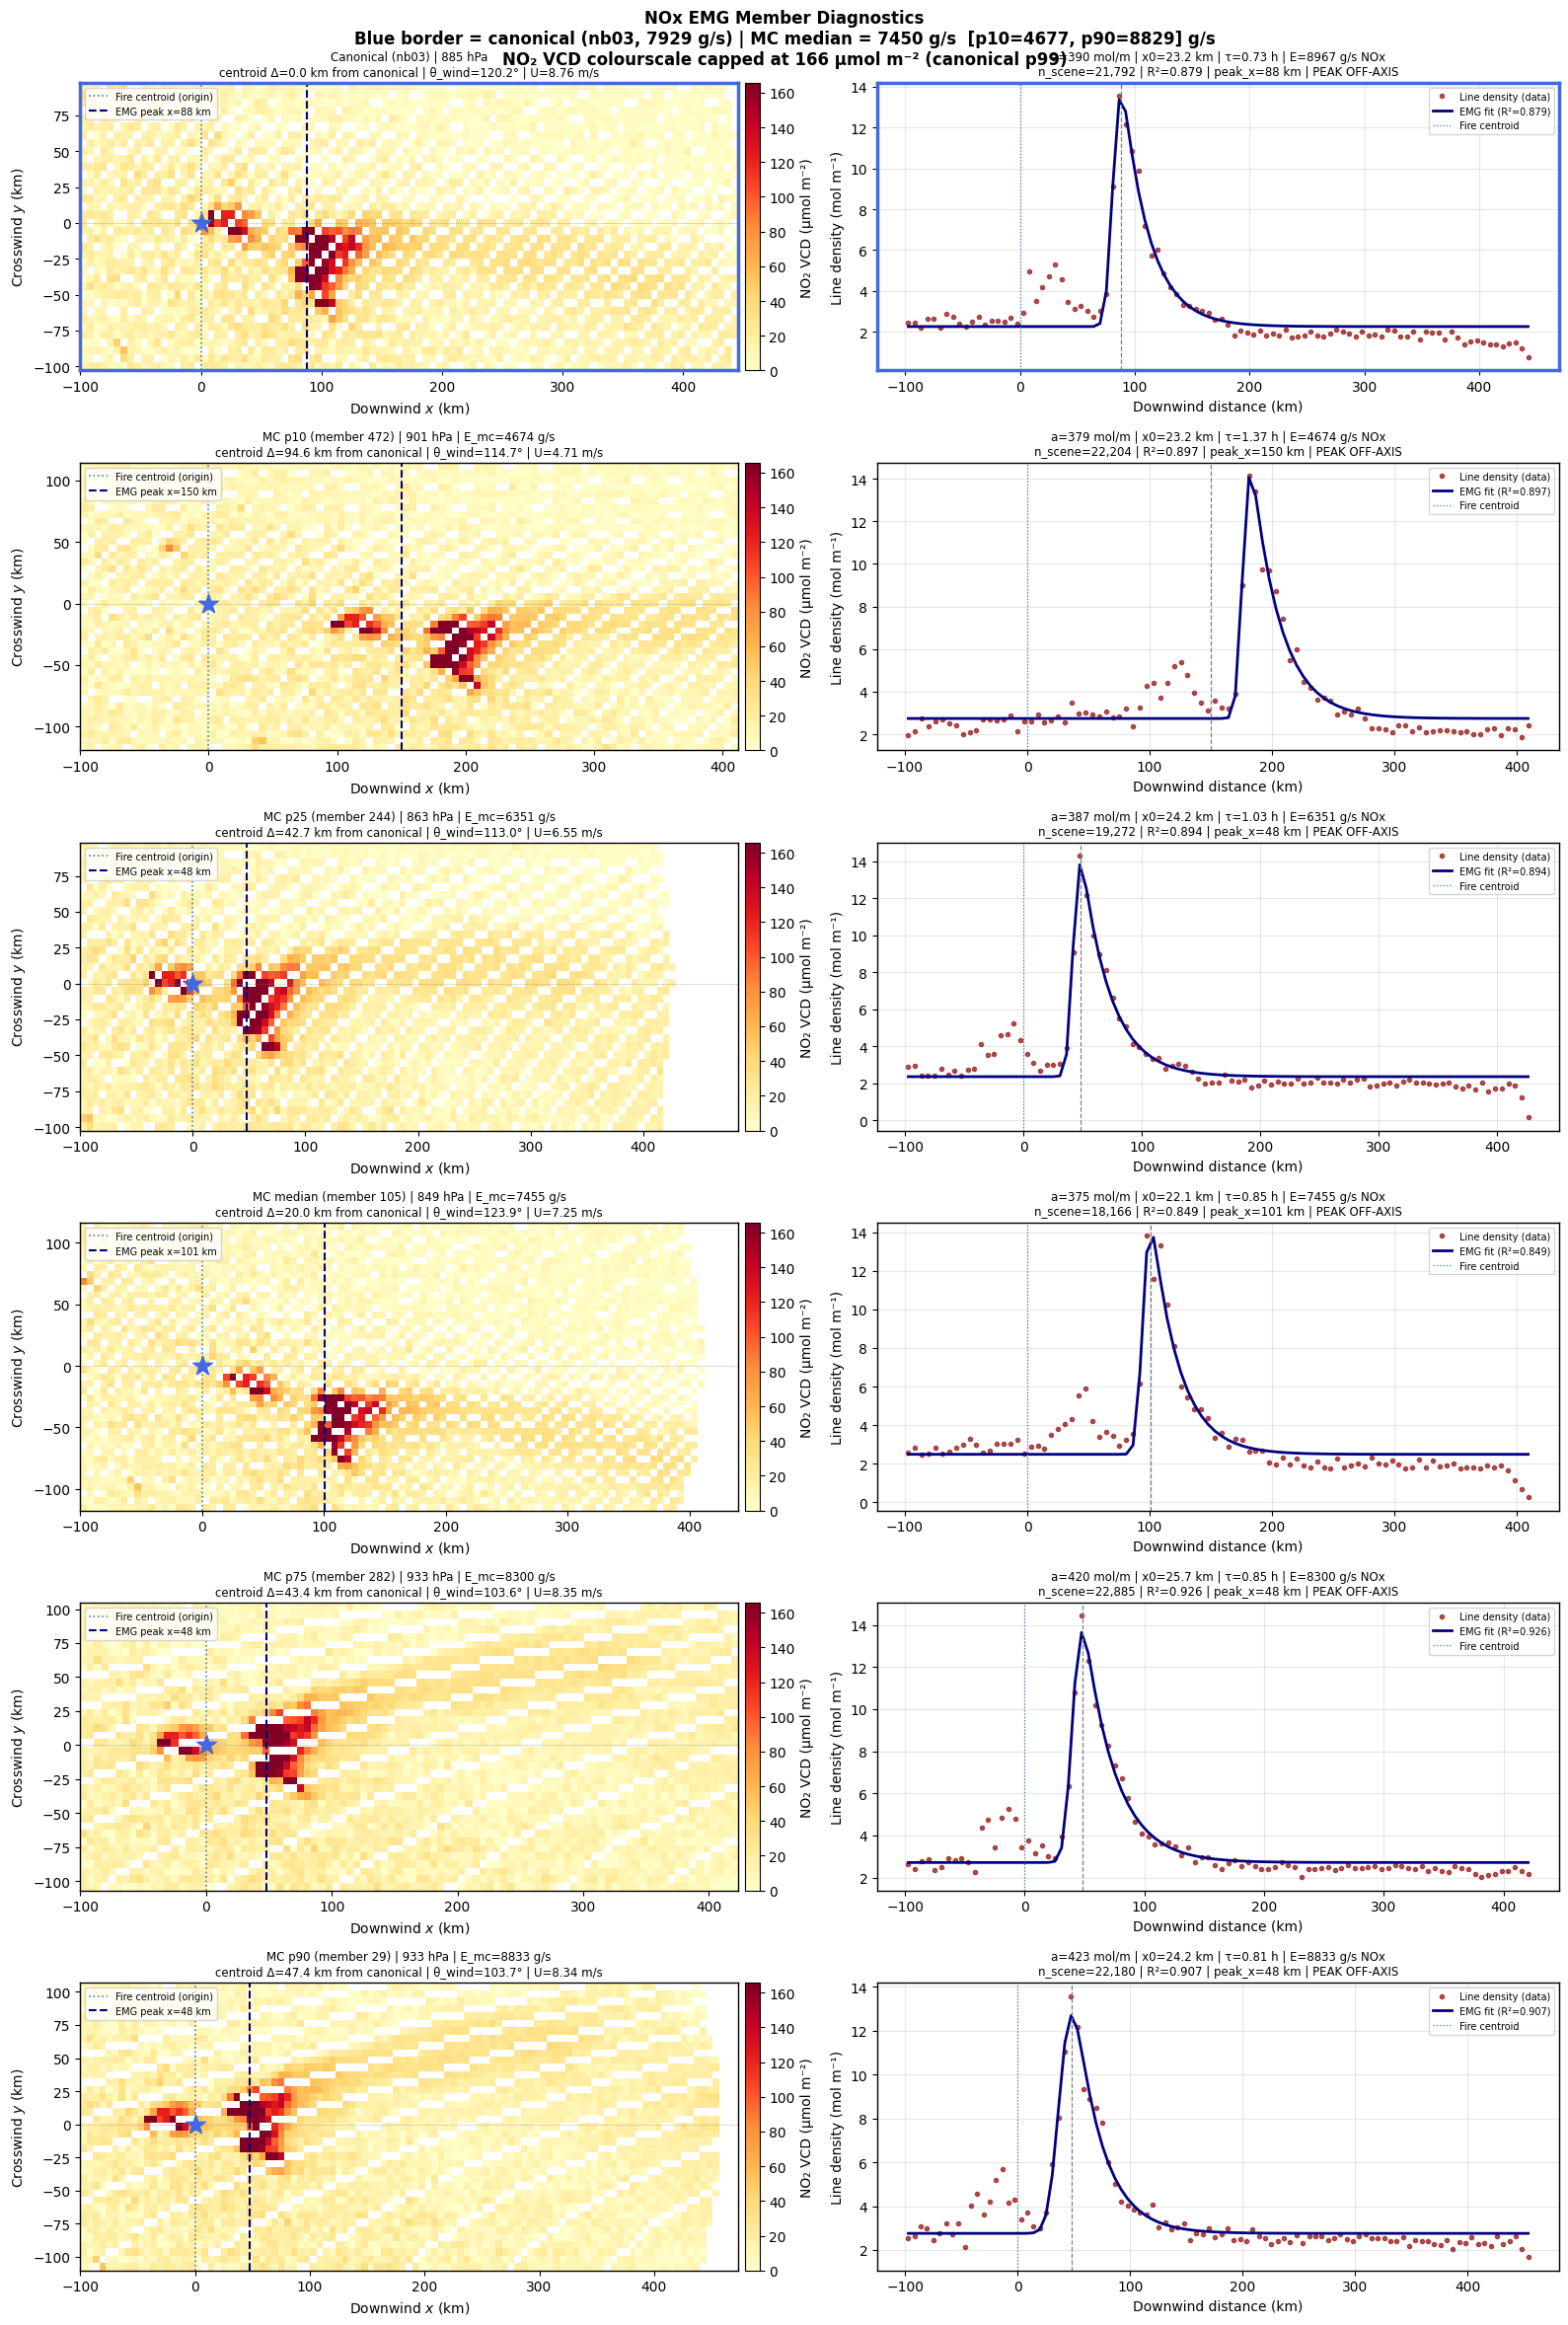

Saved: /Users/maperezc/Downloads/wildfires/outputs/error_mc/0118/nox_member_diagnostics.png


In [19]:
# ── Figure: map + EMG profile for each member ─────────────────────────────
# Determine NO₂ VMAX from canonical scene (for a consistent colourscale)
vmax_no2 = 25.0  # fallback
for m, r in zip(showcase, emg_results):
    if m.get('is_canonical') and 'error' not in r:
        pos = r['grid_mean'][r['grid_mean'] > 0]
        vmax_no2 = float(np.nanpercentile(pos, 99)) * 1e6 if pos.size else 25.0
        vmax_no2 = max(vmax_no2, 5.0)
        break

N   = len(showcase)
fig, axes = plt.subplots(N, 2, figsize=(16, 4.0 * N))
fig.suptitle(
    f'NOx EMG Member Diagnostics\n'
    f'Blue border = canonical (nb03, 7929 g/s) | '
    f'MC median = {np.median(E_arr):.0f} g/s  '
    f'[p10={np.percentile(E_arr,10):.0f}, p90={np.percentile(E_arr,90):.0f}] g/s\n'
    f'NO₂ VCD colourscale capped at {vmax_no2:.0f} μmol m⁻² (canonical p99)',
    fontsize=12, fontweight='bold',
)

for i, (m, r) in enumerate(zip(showcase, emg_results)):
    ax_map, ax_prof = axes[i, 0], axes[i, 1]
    border_c = 'royalblue' if m.get('is_canonical') else 'black'
    bw = 2.5 if m.get('is_canonical') else 1.0

    if 'error' in r:
        for ax in (ax_map, ax_prof):
            ax.text(0.5, 0.5, f"FAILED\n{r['error']}",
                    ha='center', va='center',
                    transform=ax.transAxes, color='red', fontsize=10)
            for sp in ax.spines.values():
                sp.set_edgecolor('red'); sp.set_linewidth(2)
        continue

    d_km = np.hypot(
        (m['fire_lon'] - FIRE_LON) * 111.32 * np.cos(np.radians(FIRE_LAT)),
        (m['fire_lat'] - FIRE_LAT) * 111.32,
    )

    # ── Left panel: rotated NO₂ field ─────────────────────────────────────
    im = ax_map.pcolormesh(
        r['x_centres'], r['y_centres'], r['grid_mean'].T * 1e6,
        cmap='YlOrRd', vmin=0, vmax=vmax_no2, shading='auto',
    )
    ax_map.axhline(0, color='gray', lw=0.5, ls=':')
    ax_map.axvline(0, color='steelblue', lw=1.2, ls=':',
                   label='Fire centroid (origin)')
    ax_map.axvline(r['peak_x_km'], color='navy', lw=1.5, ls='--',
                   label=f"EMG peak x={r['peak_x_km']:.0f} km")
    ax_map.scatter(0, 0, marker='*', s=220, c='royalblue', zorder=10)
    plt.colorbar(im, ax=ax_map, label='NO₂ VCD (μmol m⁻²)',
                 fraction=0.025, pad=0.01)
    ax_map.set_xlabel('Downwind $x$ (km)')
    ax_map.set_ylabel('Crosswind $y$ (km)')
    ax_map.legend(fontsize=7, loc='upper left')
    ax_map.set_title(
        f"{m['label']}\n"
        f"centroid Δ={d_km:.1f} km from canonical | "
        f"θ_wind={m['theta_wind_deg']:.1f}° | U={m['wind_speed']:.2f} m/s",
        fontsize=8.5,
    )
    for sp in ax_map.spines.values():
        sp.set_edgecolor(border_c); sp.set_linewidth(bw)

    # ── Right panel: line density + EMG fit ───────────────────────────────
    ax_prof.plot(r['x_fit'], r['y_fit'], 'o', ms=3,
                 color='darkred', alpha=0.65, label='Line density (data)')
    ax_prof.plot(r['x_fit'], r['y_pred'], '-', lw=2,
                 color='navy', label=f"EMG fit (R²={r['r2']:.3f})")
    ax_prof.axvline(0, color='steelblue', lw=0.9, ls=':',
                    label='Fire centroid')
    ax_prof.axvline(r['peak_x_km'], color='gray', lw=0.9, ls='--')
    ax_prof.set_xlabel('Downwind distance (km)')
    ax_prof.set_ylabel('Line density (mol m⁻¹)')
    ax_prof.set_title(
        f"a={r['a_mol_per_m']:.0f} mol/m | x0={r['x0_km']:.1f} km | "
        f"τ={r['tau_h']:.2f} h | E={r['E_nox_g_per_s']:.0f} g/s NOx\n"
        f"n_scene={r['n_scene']:,} | R²={r['r2']:.3f} | "
        f"peak_x={r['peak_x_km']:.0f} km | "
        f"{'PEAK OFF-AXIS' if not r['peak_within_30km'] else 'peak OK'}",
        fontsize=8.5,
    )
    ax_prof.legend(fontsize=7)
    ax_prof.grid(alpha=0.3)
    for sp in ax_prof.spines.values():
        sp.set_edgecolor(border_c); sp.set_linewidth(bw)

fig.tight_layout()
fig_path = OUT_DIR / 'nox_member_diagnostics.png'
fig.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {fig_path}')

In [20]:
# ── Summary comparison table ──────────────────────────────────────────────
rows = []
for m, r in zip(showcase, emg_results):
    d_km = np.hypot(
        (m['fire_lon'] - FIRE_LON) * 111.32 * np.cos(np.radians(FIRE_LAT)),
        (m['fire_lat'] - FIRE_LAT) * 111.32,
    )
    tag = m['label'].split('|')[0].strip()
    if 'error' in r:
        rows.append({'member': tag, 'status': 'FAILED', 'error': r['error']})
        continue
    rows.append({
        'member':           tag,
        'p_hpa':            f"{m['pressure_hpa']:.0f}",
        'U_ms':             f"{m['wind_speed']:.2f}",
        'theta_deg':        f"{m['theta_wind_deg']:.1f}",
        'centroid_Dkm':     f'{d_km:.1f}',
        'E_stored_gs':      f"{m['E_nox_g_per_s']:.0f}",
        'E_rerun_gs':       f"{r['E_nox_g_per_s']:.0f}",
        'x0_km':            f"{r['x0_km']:.1f}",
        'a_molm':           f"{r['a_mol_per_m']:.0f}",
        'tau_h':            f"{r['tau_h']:.2f}",
        'R2':               f"{r['r2']:.3f}",
        'peak_x_km':        f"{r['peak_x_km']:.0f}",
        'n_scene':          f"{r['n_scene']:,}",
        'peak_within_30km': str(r['peak_within_30km']),
    })

tbl = pd.DataFrame(rows)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
print(tbl.to_string(index=False))

# Key insight summary
print('\n── Key insight summary ──')
canon_r = emg_results[0]
if 'error' not in canon_r:
    canon_E = canon_r['E_nox_g_per_s']
    print(f'Canonical E (re-run, full pixels): {canon_E:.0f} g/s')
    for m, r in zip(showcase[1:], emg_results[1:]):
        tag = m['label'].split('|')[0].strip()
        if 'error' in r:
            print(f'  {tag:35s}: FAILED')
        else:
            ratio = r['E_nox_g_per_s'] / canon_E
            print(f"  {tag:35s}: E={r['E_nox_g_per_s']:.0f} g/s  "
                  f"({ratio:.2f}× canonical)  U={m['wind_speed']:.2f} m/s  "
                  f"x0={r['x0_km']:.1f} km")


                member p_hpa U_ms theta_deg centroid_Dkm E_stored_gs E_rerun_gs x0_km a_molm tau_h    R2 peak_x_km n_scene peak_within_30km
      Canonical (nb03)   885 8.76     120.2          0.0        7929       8967  23.2    390  0.73 0.879        88  21,792            False
   MC p10 (member 472)   901 4.71     114.7         94.6        4674       4674  23.2    379  1.37 0.897       150  22,204            False
   MC p25 (member 244)   863 6.55     113.0         42.7        6351       6351  24.2    387  1.03 0.894        48  19,272            False
MC median (member 105)   849 7.25     123.9         20.0        7455       7455  22.1    375  0.85 0.849       101  18,166            False
   MC p75 (member 282)   933 8.35     103.6         43.4        8300       8300  25.7    420  0.85 0.926        48  22,885            False
    MC p90 (member 29)   933 8.34     103.7         47.4        8833       8833  24.2    423  0.81 0.907        48  22,180            False

── Key insight summ